# PRCP-1017 — Automobile Price Prediction
### Complete Data Analysis, Predictive Modeling & Model Comparison Report

**Dataset:** 1985 Auto Imports Database (205 instances, 26 attributes) — UCI Machine Learning Repository
**Objective:** Build a model that explains and predicts car `price` from its technical and categorical specifications, so that management can understand pricing dynamics and use the model to guide design/business decisions.

**Notebook contents**
1. Imports & Data Loading
2. Data Cleaning — Missing Value Treatment
3. Exploratory Data Analysis (EDA)
4. Feature Engineering & Preprocessing
5. Model Building — 8 candidate regression algorithms
6. Model Comparison Report
7. Best Model — Feature Importance & Diagnostics
8. Report on Challenges Faced
9. Conclusion & Business Recommendations


## 1. Imports & Data Loading

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

print("Libraries loaded.")

Libraries loaded.


In [8]:
# The raw CSV has no header row; attribute names/order taken from auto_imports_names.txt
cols = ['symboling','normalized-losses','make','fuel-type','aspiration','num-of-doors',
        'body-style','drive-wheels','engine-location','wheel-base','length','width','height',
        'curb-weight','engine-type','num-of-cylinders','engine-size','fuel-system','bore',
        'stroke','compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price']
import os
df = pd.read_csv (os.path.expanduser("~/Downloads/Data/auto_imports.csv"), header=None, names=cols, na_values='?')
print("Shape:", df.shape)
df.head()

Shape: (201, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [9]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               201 non-null    object 
 3   fuel-type          201 non-null    object 
 4   aspiration         201 non-null    object 
 5   num-of-doors       199 non-null    object 
 6   body-style         201 non-null    object 
 7   drive-wheels       201 non-null    object 
 8   engine-location    201 non-null    object 
 9   wheel-base         201 non-null    float64
 10  length             201 non-null    float64
 11  width              201 non-null    float64
 12  height             201 non-null    float64
 13  curb-weight        201 non-null    int64  
 14  engine-type        201 non-null    object 
 15  num-of-cylinders   201 non-null    object 
 16  engine-size        201 non

## 2. Data Cleaning — Missing Value Treatment

The dataset uses `"?"` to mark missing values, converted to `NaN` on load. Missing counts per the dataset documentation (and confirmed below):

| Attribute | # missing |
|---|---|
| normalized-losses | 37 (in this 201-row extract) |
| num-of-doors | 2 |
| bore | 4 |
| stroke | 4 |
| horsepower | 2 |
| peak-rpm | 2 |

`price` (the target) has no missing values in this extract, so no rows need to be dropped for the target.


In [11]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

normalized-losses    37
bore                  4
stroke                4
num-of-doors          2
horsepower            2
peak-rpm              2
dtype: int64


In [12]:
# num-of-doors: only 2 missing -> impute with the most frequent value within the same body-style
df['num-of-doors'] = df.groupby('body-style')['num-of-doors'].transform(
    lambda x: x.fillna(x.mode()[0]) if not x.mode().empty else x)

# normalized-losses: 37 missing (~18%) -> impute with the median within the same risk (symboling) group,
# since normalized-losses is closely tied to the insurance risk rating
df['normalized-losses'] = df.groupby('symboling')['normalized-losses'].transform(lambda x: x.fillna(x.median()))
df['normalized-losses'] = df['normalized-losses'].fillna(df['normalized-losses'].median())

# bore, stroke, horsepower, peak-rpm: few missing (2-4 rows) -> median imputation is safe and stable
for c in ['bore', 'stroke', 'horsepower', 'peak-rpm']:
    df[c] = df[c].fillna(df[c].median())

print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


In [13]:
# Convert word-based ordinal counts to numeric (these are inherently ordered quantities)
word_to_num = {'two':2, 'three':3, 'four':4, 'five':5, 'six':6, 'eight':8, 'twelve':12}
df['num-of-doors-n'] = df['num-of-doors'].map(word_to_num)
df['num-of-cylinders-n'] = df['num-of-cylinders'].map(word_to_num)

df[['num-of-doors','num-of-doors-n','num-of-cylinders','num-of-cylinders-n']].head()

,num-of-doors,num-of-doors-n,num-of-cylinders,num-of-cylinders-n
0,two,2,four,4
1,two,2,four,4
2,two,2,six,6
3,four,4,four,4
4,four,4,five,5


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
symboling,201.0,0.840796,1.254802,-2.00,0.00,1.00,2.00,3.00
normalized-losses,201.0,121.651741,33.294528,65.00,95.00,115.00,150.00,256.00
wheel-base,201.0,98.797015,6.066366,86.60,94.50,97.00,102.40,120.90
length,201.0,174.200995,12.322175,141.10,166.80,173.20,183.50,208.10
width,201.0,65.889055,2.101471,60.30,64.10,65.50,66.60,72.00
height,201.0,53.766667,2.447822,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.666667,517.296727,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.875622,41.546834,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.330299,0.268088,2.54,3.15,3.31,3.58,3.94
stroke,201.0,3.257562,0.316082,2.07,3.11,3.29,3.41,4.17


## 3. Exploratory Data Analysis

### 3.1 Target variable — `price`
`price` is right-skewed: most cars cluster in the affordable range, with a long tail of premium/luxury models. This motivates trying models that don't assume linearity/normality (tree ensembles), alongside linear baselines.


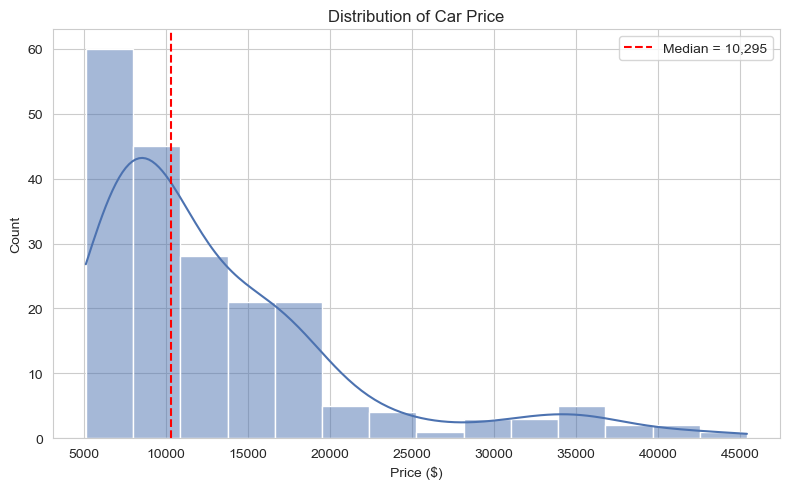

count      201.000000
mean     13207.129353
std       7947.066342
min       5118.000000
25%       7775.000000
50%      10295.000000
75%      16500.000000
max      45400.000000
Name: price, dtype: float64


In [15]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'], kde=True, color='#4C72B0')
plt.axvline(df['price'].median(), color='red', linestyle='--', label=f"Median = {df['price'].median():,.0f}")
plt.title('Distribution of Car Price')
plt.xlabel('Price ($)')
plt.legend()
plt.tight_layout()
plt.show()

print(df['price'].describe())

### 3.2 Correlation with price (numeric features)

`engine-size`, `curb-weight` and `horsepower` are the strongest positive drivers of price; `city-mpg`/`highway-mpg` are strongly negative (bigger, more powerful cars are less fuel-efficient and cost more).


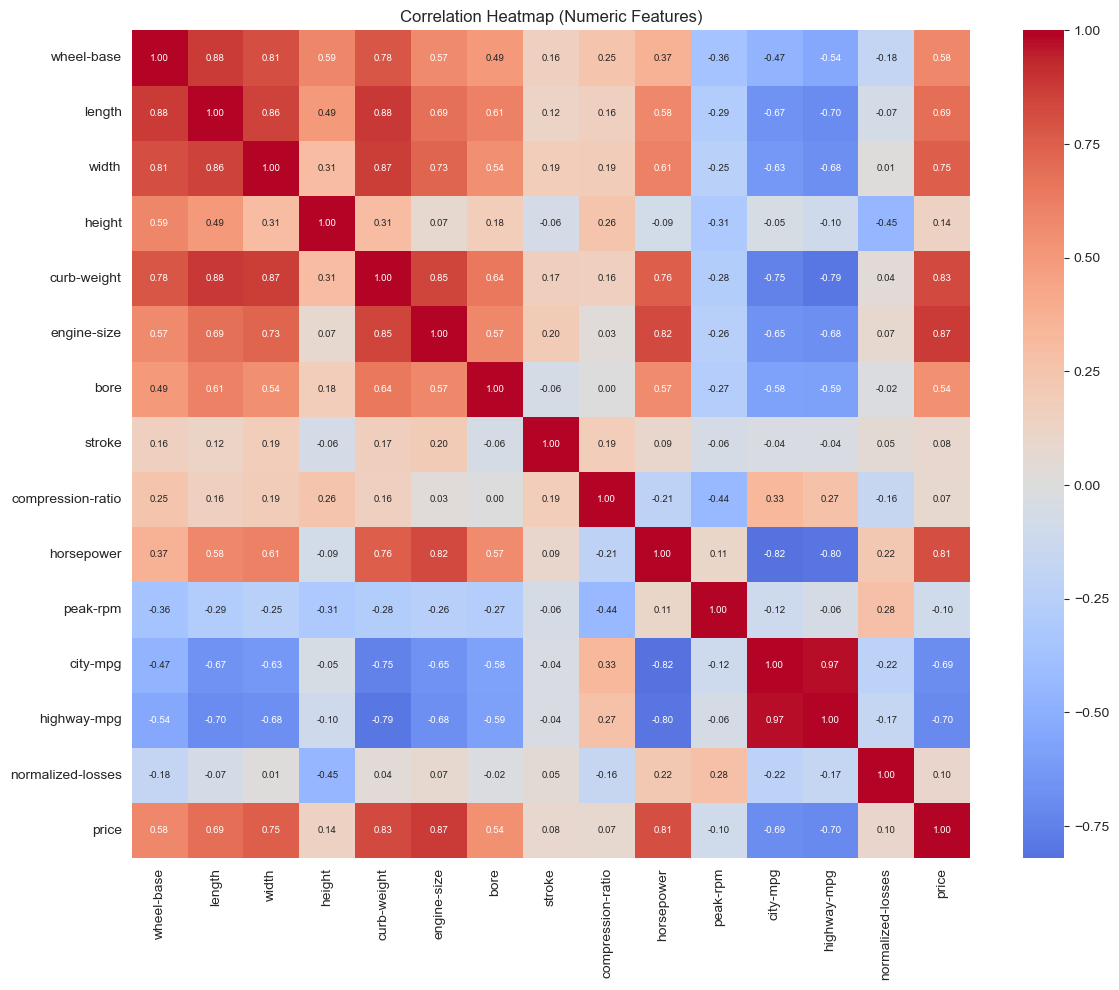

Correlation of each feature with price, sorted:
price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.810500
width                0.751265
length               0.690628
wheel-base           0.584642
bore                 0.543158
height               0.135486
normalized-losses    0.099969
stroke               0.082209
compression-ratio    0.071107
peak-rpm            -0.102310
city-mpg            -0.686571
highway-mpg         -0.704692
Name: price, dtype: float64


In [16]:
num_cols = ['wheel-base','length','width','height','curb-weight','engine-size','bore','stroke',
            'compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','normalized-losses','price']

plt.figure(figsize=(12,10))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={"size":7})
plt.title('Correlation Heatmap (Numeric Features)')
plt.tight_layout()
plt.show()

print("Correlation of each feature with price, sorted:")
print(corr['price'].sort_values(ascending=False))

### 3.3 Price vs. key continuous predictors

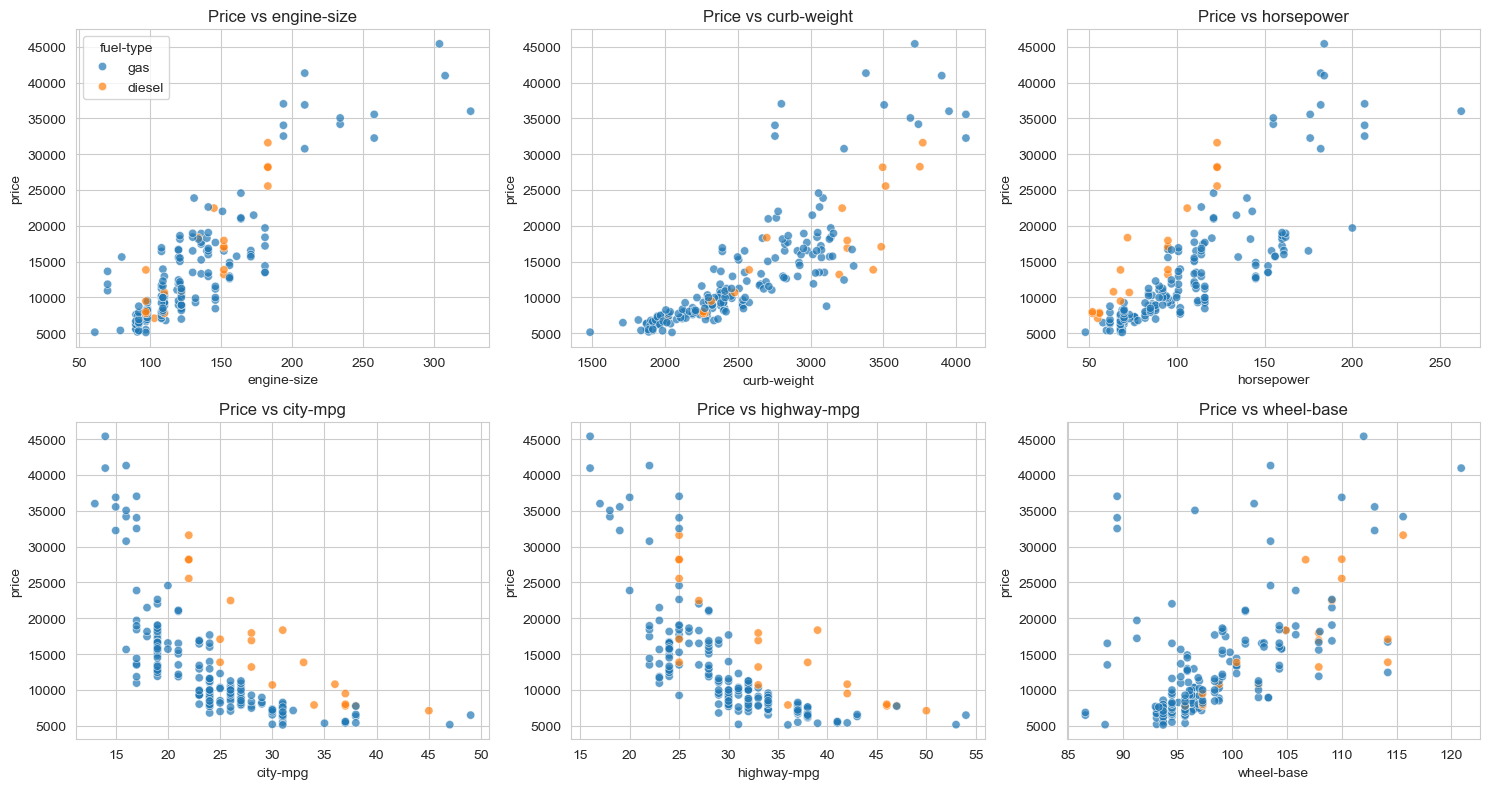

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))
plot_vars = ['engine-size','curb-weight','horsepower','city-mpg','highway-mpg','wheel-base']
for ax, c in zip(axes.flatten(), plot_vars):
    sns.scatterplot(data=df, x=c, y='price', hue='fuel-type', ax=ax, alpha=0.7, legend=(c=='engine-size'))
    ax.set_title(f'Price vs {c}')
plt.tight_layout()
plt.show()

### 3.4 Price across categorical features

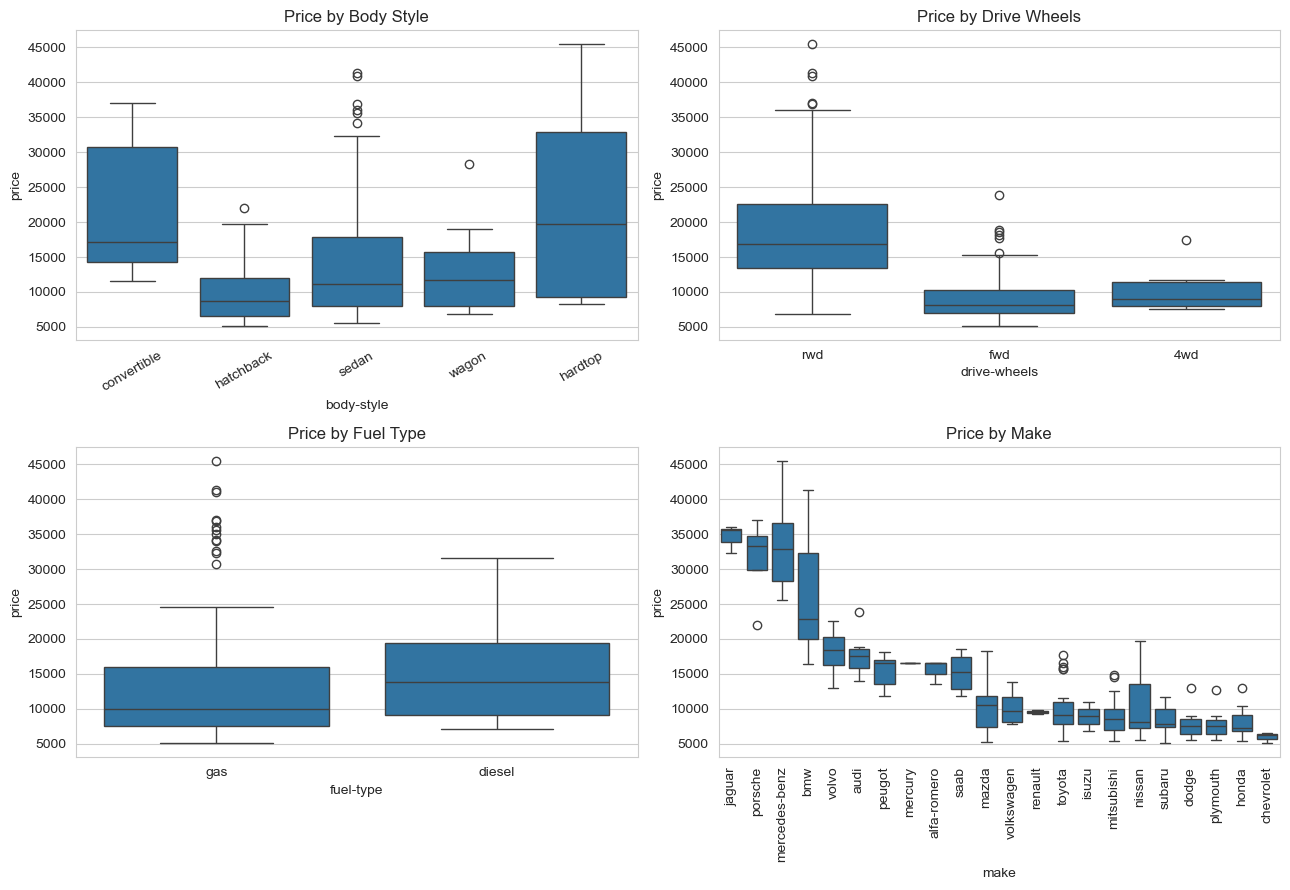

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13,9))
sns.boxplot(data=df, x='body-style', y='price', ax=axes[0,0]); axes[0,0].set_title('Price by Body Style'); axes[0,0].tick_params(axis='x', rotation=30)
sns.boxplot(data=df, x='drive-wheels', y='price', ax=axes[0,1]); axes[0,1].set_title('Price by Drive Wheels')
sns.boxplot(data=df, x='fuel-type', y='price', ax=axes[1,0]); axes[1,0].set_title('Price by Fuel Type')
make_order = df.groupby('make')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='make', y='price', order=make_order, ax=axes[1,1]); axes[1,1].set_title('Price by Make'); axes[1,1].tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

**EDA takeaways**
- Price is right-skewed with a long tail of premium makes (Mercedes-Benz, BMW, Jaguar, Porsche).
- `engine-size`, `curb-weight`, `horsepower`, `width` and `length` correlate strongly (positively) with price; `city-mpg`/`highway-mpg` correlate strongly (negatively).
- Several numeric predictors are highly correlated with **each other** (e.g. length/width/curb-weight/engine-size) — multicollinearity to keep in mind for linear models.
- `rwd` (rear-wheel-drive) and convertible/hardtop body styles command a price premium; `fwd` and hatchbacks are cheaper on average.
- diesel cars trend slightly higher due to a smaller, more premium sample rather than fuel type itself.


## 4. Feature Engineering & Preprocessing

- Ordinal word-counts (`num-of-doors`, `num-of-cylinders`) already converted to numeric.
- Remaining nominal categoricals (`make`, `fuel-type`, `aspiration`, `body-style`, `drive-wheels`, `engine-location`, `engine-type`, `fuel-system`) are one-hot encoded.
- Numeric features are standardized (zero mean/unit variance) — required for linear/SVR/KNN models and harmless for tree ensembles.
- All transforms are wrapped in a single `ColumnTransformer` + `Pipeline` so that preprocessing is fit **only on the training fold** in every case (no leakage), including during cross-validation.


In [19]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model_df = df.drop(columns=['num-of-doors', 'num-of-cylinders'])  # superseded by numeric versions

nominal_cats = ['make','fuel-type','aspiration','body-style','drive-wheels','engine-location','engine-type','fuel-system']
numeric_feats = ['symboling','normalized-losses','wheel-base','length','width','height','curb-weight',
                  'engine-size','bore','stroke','compression-ratio','horsepower','peak-rpm','city-mpg',
                  'highway-mpg','num-of-doors-n','num-of-cylinders-n']

X = model_df[numeric_feats + nominal_cats]
y = model_df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_feats),
    ('cat', OneHotEncoder(handle_unknown='ignore'), nominal_cats)
])
print("Preprocessing pipeline ready.")

Train shape: (160, 25)  Test shape: (41, 25)
Preprocessing pipeline ready.


## 5. Model Building

Eight regression algorithms are compared, spanning linear, regularized-linear, instance-based, kernel, single-tree and ensemble-tree families:

1. Linear Regression
2. Ridge Regression (L2)
3. Lasso Regression (L1)
4. Decision Tree Regressor
5. Random Forest Regressor
6. Gradient Boosting Regressor
7. K-Nearest Neighbors Regressor
8. Support Vector Regressor (RBF kernel)

Each model is evaluated two ways:
- **Hold-out test set** (20% of data, unseen during training) → R², MAE, RMSE
- **5-fold cross-validation R²** across the *whole* dataset → a more robust estimate given the modest sample size (201 rows)


In [20]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Lasso Regression': Lasso(alpha=10, random_state=42, max_iter=5000),
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=5),
    'SVR (RBF)': SVR(kernel='rbf', C=10000, gamma='scale'),
}

results = []
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    pred_test = pipe.predict(X_test)
    r2 = r2_score(y_test, pred_test)
    mae = mean_absolute_error(y_test, pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, pred_test))
    cv_scores = cross_val_score(pipe, X, y, cv=kf, scoring='r2')
    results.append({
        'Model': name, 'Test R2': round(r2,4), 'Test MAE': round(mae,1), 'Test RMSE': round(rmse,1),
        'CV R2 Mean': round(cv_scores.mean(),4), 'CV R2 Std': round(cv_scores.std(),4)
    })

results_df = pd.DataFrame(results).sort_values('CV R2 Mean', ascending=False).reset_index(drop=True)
print("Training complete for all 8 models.")

Training complete for all 8 models.


## 6. Model Comparison Report

The table and chart below rank all candidate models by **5-fold cross-validated R²** (the most reliable metric on this small dataset), with hold-out test-set R², MAE and RMSE shown alongside.


In [21]:
results_df

,Model,Test R2,Test MAE,Test RMSE,CV R2 Mean,CV R2 Std
0,Gradient Boosting,0.9522,1536.6,2418.8,0.8843,0.0613
1,Random Forest,0.9274,1916.3,2980.3,0.8804,0.0547
2,Lasso Regression,0.9353,1737.7,2813.5,0.8792,0.0503
3,Ridge Regression,0.9213,1916.2,3102.7,0.8733,0.0418
4,Decision Tree,0.9282,1991.2,2963.6,0.8611,0.0564
5,SVR (RBF),0.8585,2503.1,4161.1,0.8520,0.0287
6,Linear Regression,0.9359,1720.6,2800.0,0.8514,0.0715
7,KNN Regressor,0.6453,3665.0,6587.1,0.7747,0.0925


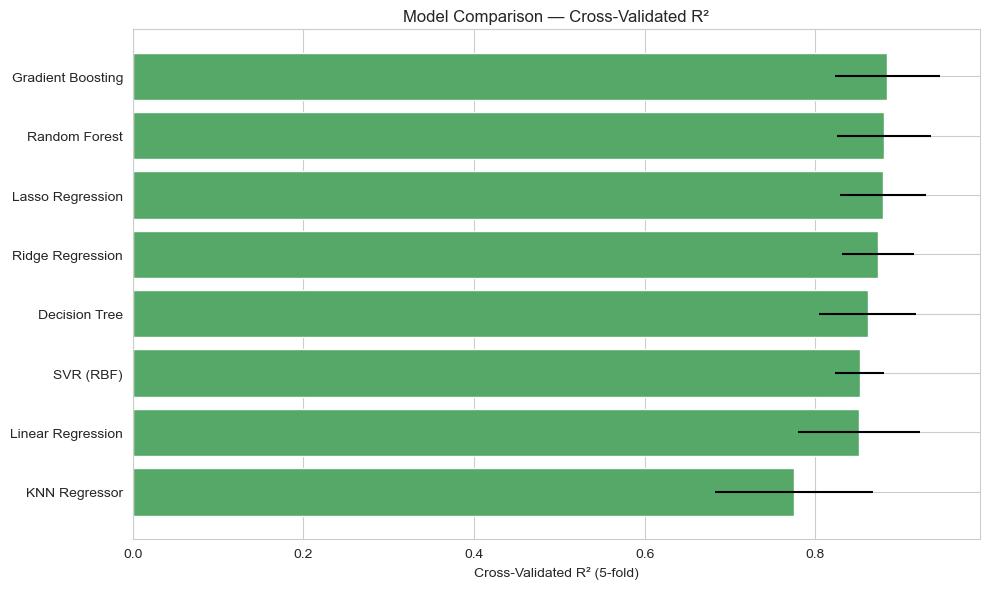

Best model by CV R2: Gradient Boosting


In [22]:
plt.figure(figsize=(10,6))
plot_df = results_df.sort_values('CV R2 Mean')
plt.barh(plot_df['Model'], plot_df['CV R2 Mean'], xerr=plot_df['CV R2 Std'], color='#55A868')
plt.xlabel('Cross-Validated R² (5-fold)')
plt.title('Model Comparison — Cross-Validated R²')
plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]['Model']
print("Best model by CV R2:", best_model_name)

**Reading the comparison:**
- **Gradient Boosting** and **Random Forest** top the ranking on cross-validated R² (~0.88), with Gradient Boosting also giving the best hold-out R² (~0.95) and the lowest MAE/RMSE — it captures non-linear effects and interactions (e.g. engine-size × curb-weight) that hurt the linear models.
- **Lasso** and **Ridge** regression are strong, simple baselines (CV R² ≈ 0.87–0.88): the regularization helps handle the multicollinearity identified in the EDA (engine-size, curb-weight, length, width are highly correlated).
- **Plain Linear Regression** is competitive on the hold-out split but has the **highest CV variance**, confirming it is more sensitive to multicollinearity and to which rows land in the training fold.
- **KNN** is clearly the weakest model — with only 201 rows spread across a high-dimensional one-hot-encoded feature space, distance-based neighbors become unreliable (the curse of dimensionality).
- **SVR** underperforms the tree ensembles here; kernel SVR needs more careful tuning of `C`/`gamma`/`epsilon` than a general default provides.

**Recommendation for production: Gradient Boosting Regressor.** It gives the best accuracy on both hold-out and cross-validated metrics, degrades gracefully with the multicollinear/mixed-type features, and (as shown next) yields directly interpretable feature importances that management can act on — a Random Forest is a very close, slightly more stable runner-up if a lower-variance model is preferred.


## 7. Best Model — Feature Importance & Diagnostics

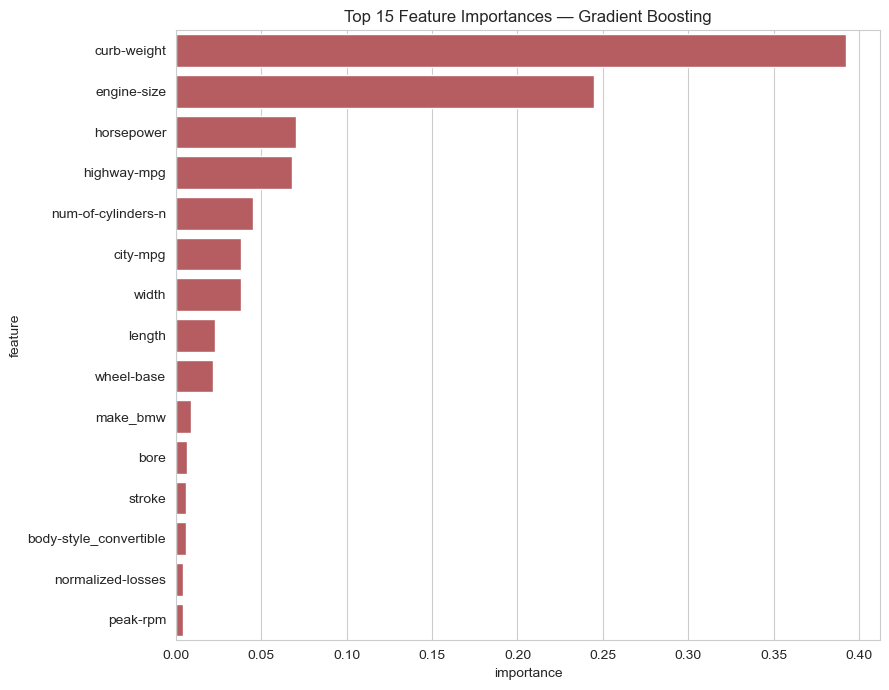

,feature,importance
6,curb-weight,0.392642
7,engine-size,0.244881
11,horsepower,0.070467
14,highway-mpg,0.067969
16,num-of-cylinders-n,0.045047
13,city-mpg,0.038219
4,width,0.038052
3,length,0.022609
2,wheel-base,0.021822
19,make_bmw,0.008636


In [23]:
best_pipe = Pipeline([('prep', preprocess), ('model', models[best_model_name])])
best_pipe.fit(X_train, y_train)

ohe = best_pipe.named_steps['prep'].named_transformers_['cat']
cat_names = list(ohe.get_feature_names_out(nominal_cats))
feat_names = numeric_feats + cat_names
importances = best_pipe.named_steps['model'].feature_importances_

imp_df = pd.DataFrame({'feature': feat_names, 'importance': importances}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(9,7))
sns.barplot(data=imp_df, x='importance', y='feature', color='#C44E52')
plt.title(f'Top 15 Feature Importances — {best_model_name}')
plt.tight_layout()
plt.show()

imp_df

`curb-weight` and `engine-size` alone account for roughly two-thirds of the model's predictive signal, followed by `horsepower`, `highway-mpg` and `num-of-cylinders`. This matches automotive-economics intuition (bigger engines and heavier, more powerful cars cost more to design and build) and gives management a clear, ranked lever list: **size/weight class and powertrain specification are the dominant price drivers**, well ahead of any single brand ("make") effect.

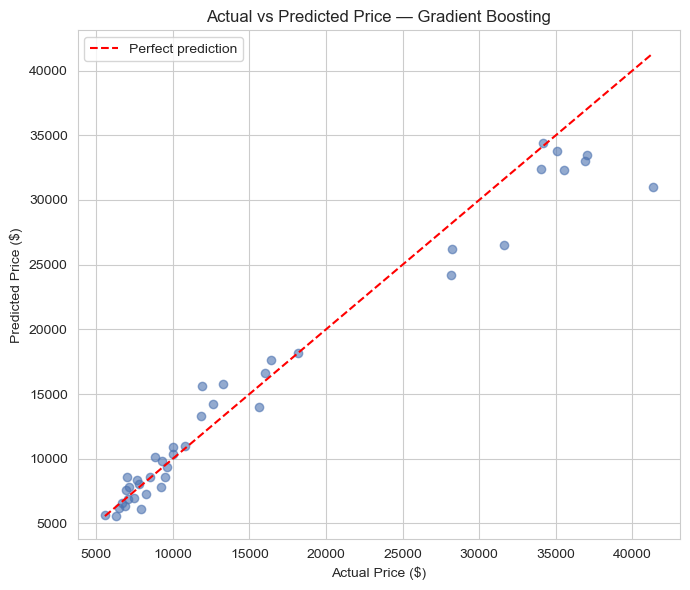

Gradient Boosting hold-out performance -> R2: 0.952 | MAE: $1,537 | RMSE: $2,419


In [24]:
pred_best = best_pipe.predict(X_test)

plt.figure(figsize=(7,6))
plt.scatter(y_test, pred_best, alpha=0.6, color='#4C72B0')
lims = [min(y_test.min(), pred_best.min()), max(y_test.max(), pred_best.max())]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual Price ($)'); plt.ylabel('Predicted Price ($)')
plt.title(f'Actual vs Predicted Price — {best_model_name}')
plt.legend(); plt.tight_layout()
plt.show()

test_r2 = r2_score(y_test, pred_best)
test_mae = mean_absolute_error(y_test, pred_best)
test_rmse = np.sqrt(mean_squared_error(y_test, pred_best))
print(f"{best_model_name} hold-out performance -> R2: {test_r2:.3f} | MAE: ${test_mae:,.0f} | RMSE: ${test_rmse:,.0f}")

## 8. Report on Challenges Faced

**1. No header row / attribute mapping.** The raw CSV ships with no column names. *Technique:* column names and order were taken directly from the accompanying `auto_imports_names.txt` data dictionary and applied on load, so every attribute is unambiguous before any analysis begins.

**2. Missing values encoded as `"?"`, not NaN.** Pandas would otherwise treat the whole column as text. *Technique:* `na_values='?'` on `read_csv` so missing cells are recognized and typed correctly (numeric columns stay numeric).

**3. Missing values concentrated unevenly.** `normalized-losses` alone was missing in ~18% of rows; `num-of-doors`, `bore`, `stroke`, `horsepower`, `peak-rpm` had only 2–4 missing each. *Technique:* rather than one blanket rule, missingness was handled attribute-by-attribute — `num-of-doors` imputed from the modal value within the same `body-style` (doors are a strong function of body style, e.g. convertibles are virtually always two-door); `normalized-losses` imputed from the median within the same `symboling` (risk rating) group, since the two are defined to be closely related; the remaining low-missing numeric columns used simple median imputation, which is stable for such small counts. Dropping rows was avoided since the dataset is already small (201 rows).

**4. Small sample size (201 rows) relative to feature count after encoding.** One-hot encoding `make` alone (22 categories) plus the other seven nominal features expands the feature space substantially, raising overfitting risk. *Technique:* favored models and settings that regularize or bag/average (Ridge/Lasso, Random Forest, Gradient Boosting with shallow trees) over high-variance choices, and relied on 5-fold cross-validated R² — not just a single hold-out split — to get a more trustworthy performance estimate.

**5. Multicollinearity among size/engine features.** `length`, `width`, `curb-weight`, `engine-size` and `wheel-base` are all mutually highly correlated (cars scale together), which destabilizes plain linear-regression coefficients. *Technique:* included Ridge/Lasso (built to handle collinearity) and tree ensembles (largely insensitive to collinearity) alongside plain linear regression, and used the mix of hold-out + cross-validated metrics to catch models with high variance across folds.

**6. Mixed data types and inconsistent categorical encodings.** Ordinal counts (`num-of-doors`, `num-of-cylinders`) were stored as English words ("four", "six") rather than numbers, and would have been mishandled if one-hot encoded like a true nominal category (losing their inherent order). *Technique:* explicitly mapped these to integers before encoding, and one-hot-encoded only the genuinely unordered nominal fields (`make`, `body-style`, etc.).

**7. Right-skewed target with a long luxury-car tail.** A few premium makes (Mercedes-Benz, Jaguar, Porsche, BMW) sit far above the bulk of the price distribution, which can pull simple linear fits away from the bulk of "ordinary" cars. *Technique:* used tree-ensemble models (Random Forest / Gradient Boosting), which split on thresholds rather than assuming a linear/normal relationship, and are more robust to this kind of skew without needing a log-transform of the target.


## 9. Conclusion & Business Recommendations

- **Best model for production:** Gradient Boosting Regressor — cross-validated R² ≈ 0.88, hold-out R² ≈ 0.95, hold-out MAE ≈ $1,540 (roughly 12% of the average car price).
- **What drives price, in order of impact:** `curb-weight` and `engine-size` dominate, followed by `horsepower`, fuel-economy (`highway-mpg`/`city-mpg`) and `num-of-cylinders`. Body-style, drive-wheels and specific `make` contribute smaller, secondary adjustments.
- **Actionable implication for management:** price is overwhelmingly a function of a car's physical size/weight class and powertrain output — not brand alone. To hit a target price point, the most reliable design levers are curb weight and engine displacement/power; fuel-economy trade-offs and specific trims are secondary levers for fine-tuning within a size class.
- **Next steps for a production rollout:** collect more recent (post-1985) and larger-volume data to reduce the small-sample variance seen in cross-validation, tune Gradient Boosting hyperparameters (learning rate, depth, n_estimators) via grid/Bayesian search, and monitor for concept drift in materials/technology costs over time.
